# Fashion Item Detection with YOLO
Train a **YOLOv8** model to detect 10 fashion items (sunglass, hat, jacket, shirt, pants, shorts, skirt, dress, bag, shoe).
The trained model (`best.pt`) is used by the *Colorful Fashion Recommendation* notebook.

## 1. Setup

In [1]:
# Import Libraries
# If ultralytics is not installed:  %pip install ultralytics
import os
import shutil
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from PIL import Image
from IPython.display import display, Image as IPyImage
from ultralytics import YOLO

## 2. Explore the Dataset

In [2]:
# Dataset check
DATASET_PATH="dataset"
image_dir=os.path.join(DATASET_PATH,"JPEGImages")
annotation_dir=os.path.join(DATASET_PATH,"Annotations")
image_files=os.listdir(image_dir)
annotation_files=os.listdir(annotation_dir)

print("Dataset exists:",os.path.exists(DATASET_PATH))
print("Total images:",len(image_files))
print("Total annotation files:",len(annotation_files))

Dataset exists: True
Total images: 2682
Total annotation files: 2682


In [3]:
# Check image-annotation matching
image_names={os.path.splitext(f)[0] for f in image_files}
annotation_names={os.path.splitext(f)[0] for f in annotation_files}
print("Images without annotation:",len(image_names-annotation_names))
print("Annotations without images:",len(annotation_names-image_names))
print("Matching pairs:",len(image_names&annotation_names))

Images without annotation: 0
Annotations without images: 0
Matching pairs: 2682


In [4]:
# Check that XML image sizes match the real image sizes (needed for correct YOLO labels)
size_mismatch=[]
for xml_file in annotation_files:
    size=ET.parse(os.path.join(annotation_dir,xml_file)).getroot().find("size")
    xml_size=(int(size.find("width").text),int(size.find("height").text))
    real_size=Image.open(os.path.join(image_dir,os.path.splitext(xml_file)[0]+".jpg")).size
    if xml_size!=real_size:
        size_mismatch.append(xml_file)

print("Images where XML size differs from real image size:",len(size_mismatch))

Images where XML size differs from real image size: 0


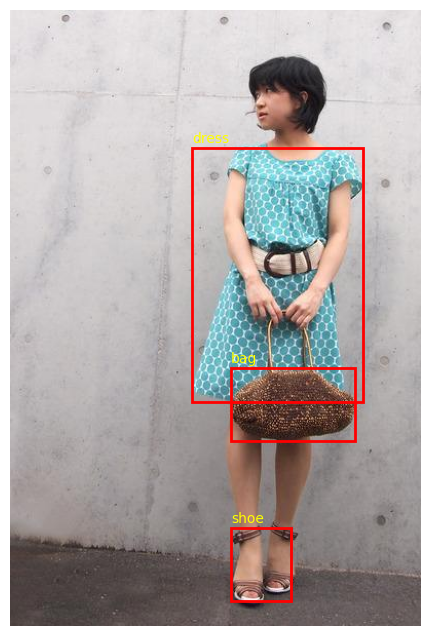

In [5]:
# Visualize image with bounding boxes
import matplotlib.patches as patches
sample_image_path=os.path.join(image_dir,"1.jpg")
sample_xml_path=os.path.join(annotation_dir,"1.xml")

image=cv2.cvtColor(cv2.imread(sample_image_path),cv2.COLOR_BGR2RGB)
root=ET.parse(sample_xml_path).getroot()
fig,ax=plt.subplots(figsize=(6,8))
ax.imshow(image)

for obj in root.findall("object"):
    name=obj.find("name").text
    box=obj.find("bndbox")

    xmin=int(box.find("xmin").text)
    ymin=int(box.find("ymin").text)
    xmax=int(box.find("xmax").text)
    ymax=int(box.find("ymax").text)

    rect=patches.Rectangle((xmin,ymin),xmax-xmin,ymax-ymin,
                           linewidth=2,edgecolor="red",facecolor="none")
    ax.add_patch(rect)
    ax.text(xmin,ymin-5,name,color="yellow",fontsize=10)
ax.axis("off")
plt.show()

In [6]:
# Check class distribution
from collections import Counter
class_counts=Counter()

for xml_file in annotation_files:
    xml_path=os.path.join(annotation_dir,xml_file)
    root=ET.parse(xml_path).getroot()

    for obj in root.findall("object"):
        class_counts[obj.find("name").text]+=1

print("Object count per class:")
for name,count in sorted(class_counts.items()):
    print(f"{name}: {count}")

Object count per class:
bag: 1462
dress: 678
hat: 350
jacket: 958
pants: 622
shirt: 1852
shoe: 2601
shorts: 502
skirt: 883
sunglass: 425


## 3. Prepare the Data for YOLO
YOLO needs one label file per image with lines of: `class_id x_center y_center width height` (values between 0 and 1).
The XML boxes are converted into this format and split into train / validation / test folders.

In [7]:
# Read train/test split files
split_dir=os.path.join(DATASET_PATH,"ImageSets","Main")
with open(os.path.join(split_dir,"trainval.txt"),"r") as file:
    trainval_ids=file.read().splitlines()

with open(os.path.join(split_dir,"test.txt"),"r") as file:
    test_ids=file.read().splitlines()

print("Trainval images:",len(trainval_ids))
print("Test images:",len(test_ids))

Trainval images: 2145
Test images: 537


In [8]:
# Split trainval into train and validation
from sklearn.model_selection import train_test_split
train_ids,val_ids=train_test_split(trainval_ids,test_size=0.2,random_state=42)
print("Training images:",len(train_ids))
print("Validation images:",len(val_ids))
print("Testing images:",len(test_ids))

Training images: 1716
Validation images: 429
Testing images: 537


In [9]:
# Define class names and class IDs
classes_list=["sunglass","hat","jacket","shirt","pants","shorts","skirt","dress","bag","shoe"]
print("Total classes:",len(classes_list))
print("Class IDs:",{name: i for i,name in enumerate(classes_list)})

Total classes: 10
Class IDs: {'sunglass': 0, 'hat': 1, 'jacket': 2, 'shirt': 3, 'pants': 4, 'shorts': 5, 'skirt': 6, 'dress': 7, 'bag': 8, 'shoe': 9}


In [10]:
# Convert XML annotations to YOLO format
def convert_xml_to_yolo(xml_path):
    root=ET.parse(xml_path).getroot()
    size=root.find("size")
    image_width=int(size.find("width").text)
    image_height=int(size.find("height").text)

    yolo_labels=[]
   
    for obj in root.findall("object"):
        class_name=obj.find("name").text
        class_id=classes_list.index(class_name)

        box=obj.find("bndbox")
        xmin=float(box.find("xmin").text)
        ymin=float(box.find("ymin").text)
        xmax=float(box.find("xmax").text)
        ymax=float(box.find("ymax").text)

        x_center=((xmin+xmax)/2)/image_width
        y_center=((ymin+ymax)/2)/image_height
        box_width=(xmax-xmin)/image_width
        box_height=(ymax-ymin)/image_height

        yolo_labels.append(f"{class_id} {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}")
                           
    return yolo_labels

In [11]:
# Create YOLO dataset images and labels
yolo_dir="yolo_dataset"
splits={"train":train_ids,"val":val_ids,"test":test_ids}

for split,ids in splits.items():
    image_folder=os.path.join(yolo_dir,"images",split)
    label_folder=os.path.join(yolo_dir,"labels",split)

    os.makedirs(image_folder,exist_ok=True)
    os.makedirs(label_folder,exist_ok=True)

    # Remove old images and label files from earlier runs
    for folder in (image_folder,label_folder):
        for file_name in os.listdir(folder):
            file_path=os.path.join(folder,file_name)
            if os.path.isfile(file_path):
                os.remove(file_path)

    for image_id in ids:
        image_name=f"{image_id}.jpg"
        xml_name=f"{image_id}.xml"

        src_image=os.path.join(image_dir,image_name)
        src_xml=os.path.join(annotation_dir,xml_name)

        dst_image=os.path.join(image_folder,image_name)
        dst_label=os.path.join(label_folder,f"{image_id}.txt")

        if os.path.exists(src_image) and os.path.exists(src_xml):
            shutil.copy2(src_image,dst_image)
            labels=convert_xml_to_yolo(src_xml)

            with open(dst_label,"w") as file:
                file.write("\n".join(labels))
    print(f"{split}: dataset labels created")

print("YOLO dataset created successfully.")

train: dataset labels created
val: dataset labels created
test: dataset labels created
YOLO dataset created successfully.


In [12]:
# Check copied images and YOLO labels
for split in ["train","val","test"]:
    image_folder=os.path.join(yolo_dir,"images",split)
    label_folder=os.path.join(yolo_dir,"labels",split)

    print(f"{split} images:",len(os.listdir(image_folder)))
    print(f"{split} labels:",len(os.listdir(label_folder)))

train images: 1716
train labels: 1716
val images: 429
val labels: 429
test images: 538
test labels: 537


In [13]:
# Create YOLO configuration file
import yaml
yolo_config={"path":os.path.abspath(yolo_dir),
             "train":"images/train",
             "val":"images/val",
             "test":"images/test",
             "names":classes_list}
yaml_path=os.path.join(yolo_dir,"fashion.yaml")
with open(yaml_path,"w") as file:
    yaml.dump(yolo_config,file,sort_keys=False)

print("YOLO configuration file creates:",yaml_path)

YOLO configuration file creates: yolo_dataset\fashion.yaml


In [14]:
# Check sample YOLO label file
sample_label_path=os.path.join(yolo_dir,"labels","train",f"{train_ids[0]}.txt")
with open(sample_label_path,"r") as file:
    print(file.read())

3 0.503750 0.324167 0.127500 0.178333
8 0.432500 0.451667 0.230000 0.123333
2 0.537500 0.509167 0.375000 0.615000
9 0.513750 0.819167 0.127500 0.081667
5 0.553750 0.451667 0.062500 0.063333
0 0.520000 0.135000 0.095000 0.060000


## 4. Train YOLOv8
Pretrained **YOLOv8n** is fine-tuned for 20 epochs at image size 320. The batch size is set to 8 because training is performed on a CPU without a GPU. Training may take around 3 hours, depending on system performance.

In [15]:
# Train YOLOv8 model
model=YOLO("yolov8n.pt")
results=model.train(data=yaml_path,epochs=20,imgsz=320,batch=8,name="fashion_yolo_fast")

C:\Anaconda3\envs\aidl\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


New https://pypi.org/project/ultralytics/8.4.184 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.182  Python-3.12.15 torch-2.14.1+cpu CPU (AMD Ryzen 3 3250U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_dataset\fashion.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, 

## 5. Evaluate the Trained Model

In [16]:
# Load the best model saved during training
best_model_path=os.path.join(str(results.save_dir), "weights","best.pt")
model=YOLO(best_model_path)
print("Trained model loaded:",best_model_path)
print("Classes:",model.names)

Trained model loaded: D:\Hope\AI Course Tamil\16. Week-11-Deep Learning Module\4.Assignment\Colorful_Fashion_Project\runs\detect\fashion_yolo_fast-3\weights\best.pt
Classes: {0: 'sunglass', 1: 'hat', 2: 'jacket', 3: 'shirt', 4: 'pants', 5: 'shorts', 6: 'skirt', 7: 'dress', 8: 'bag', 9: 'shoe'}


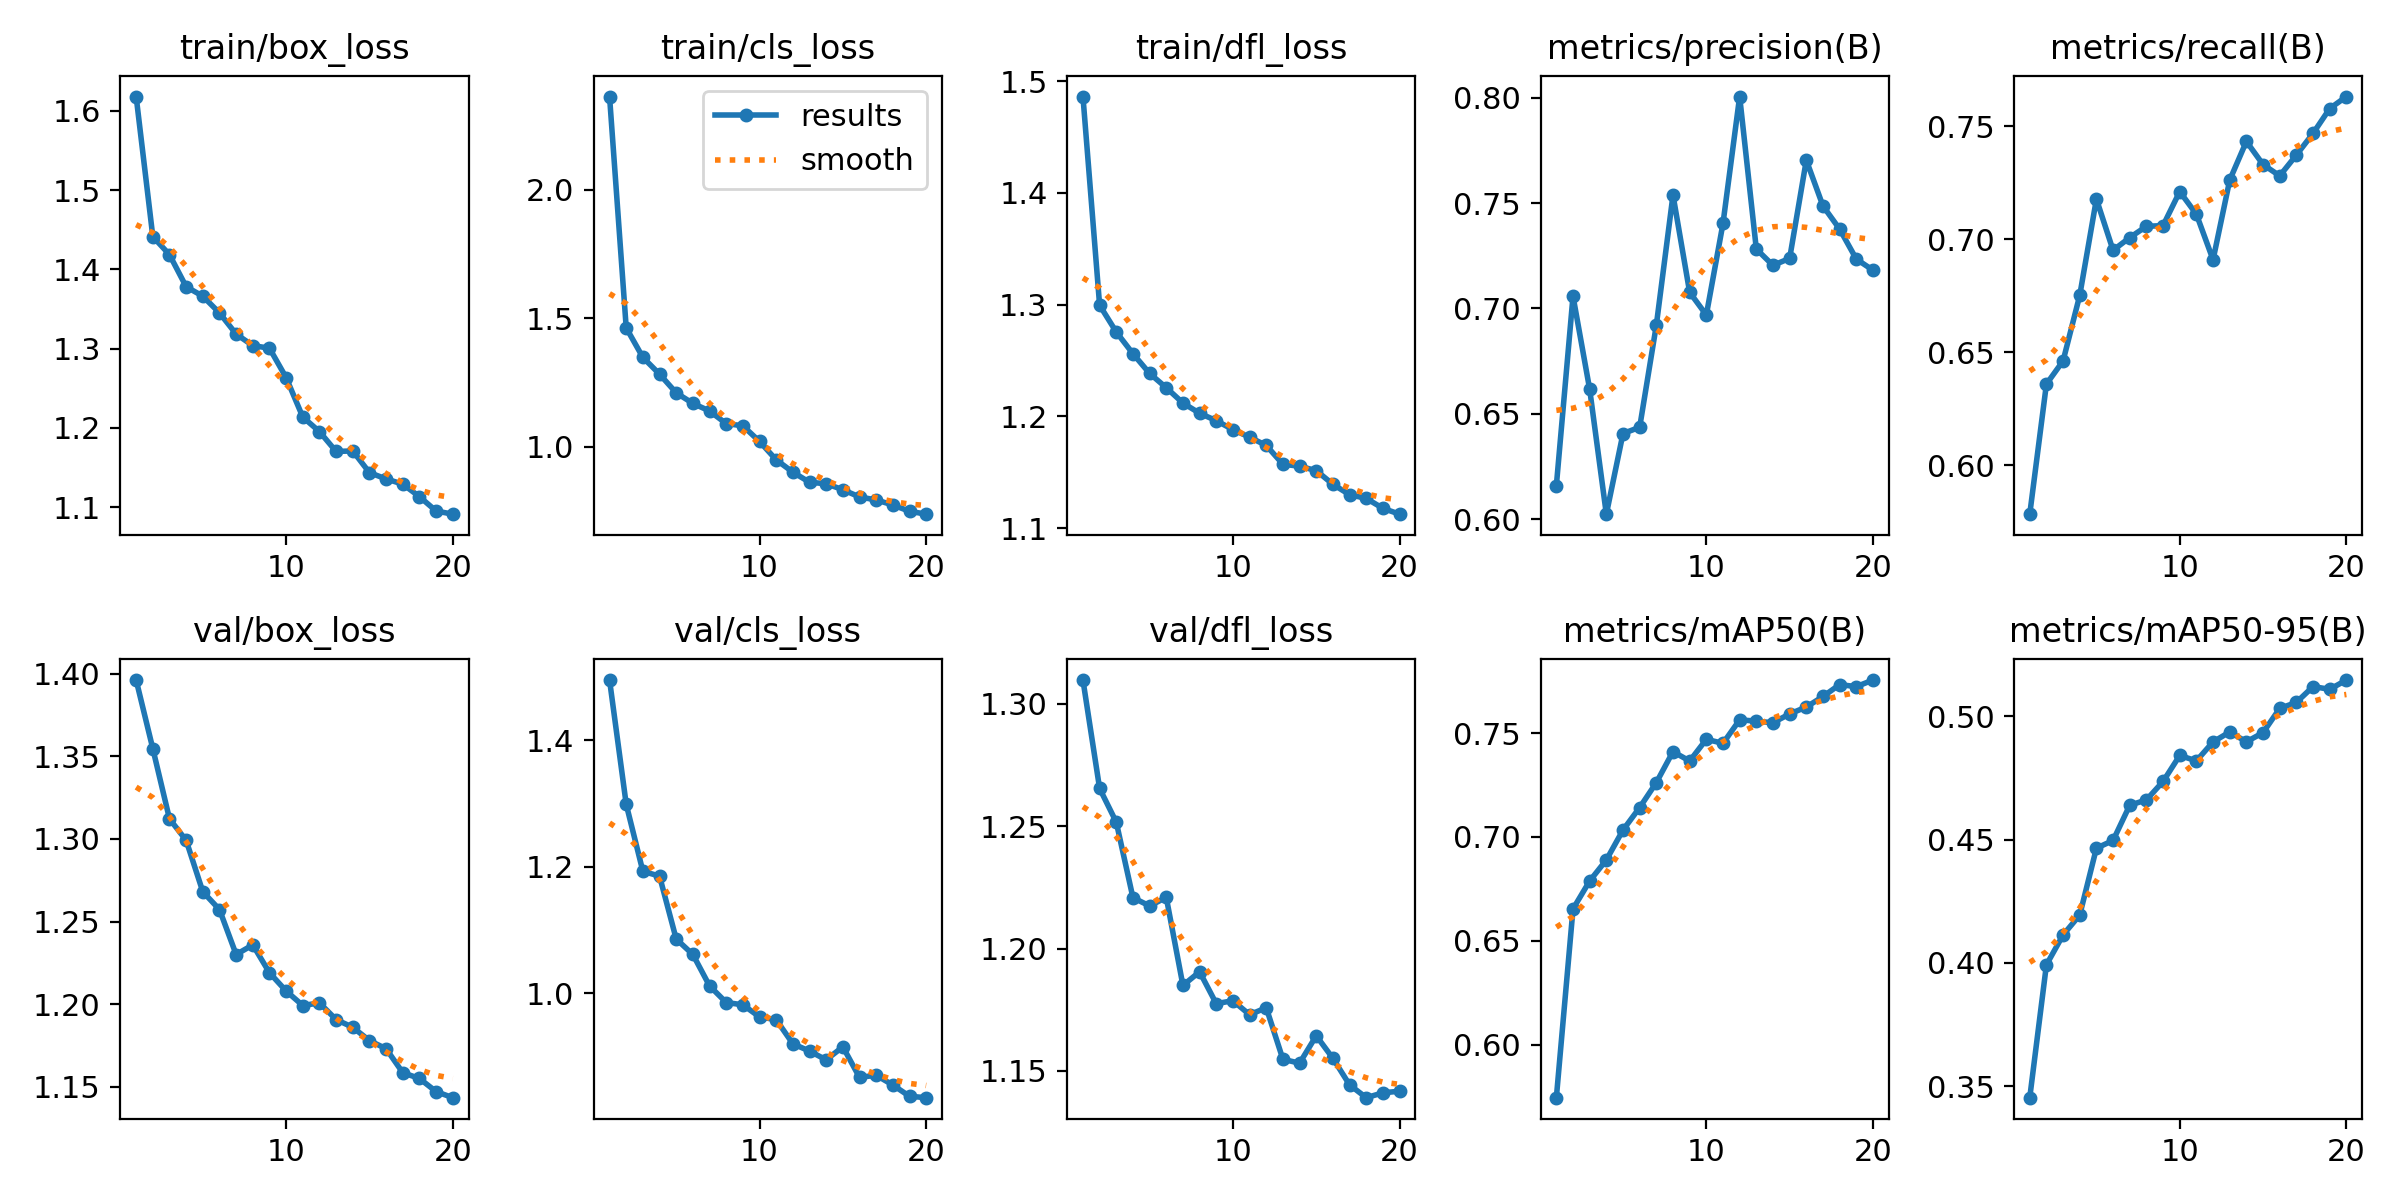

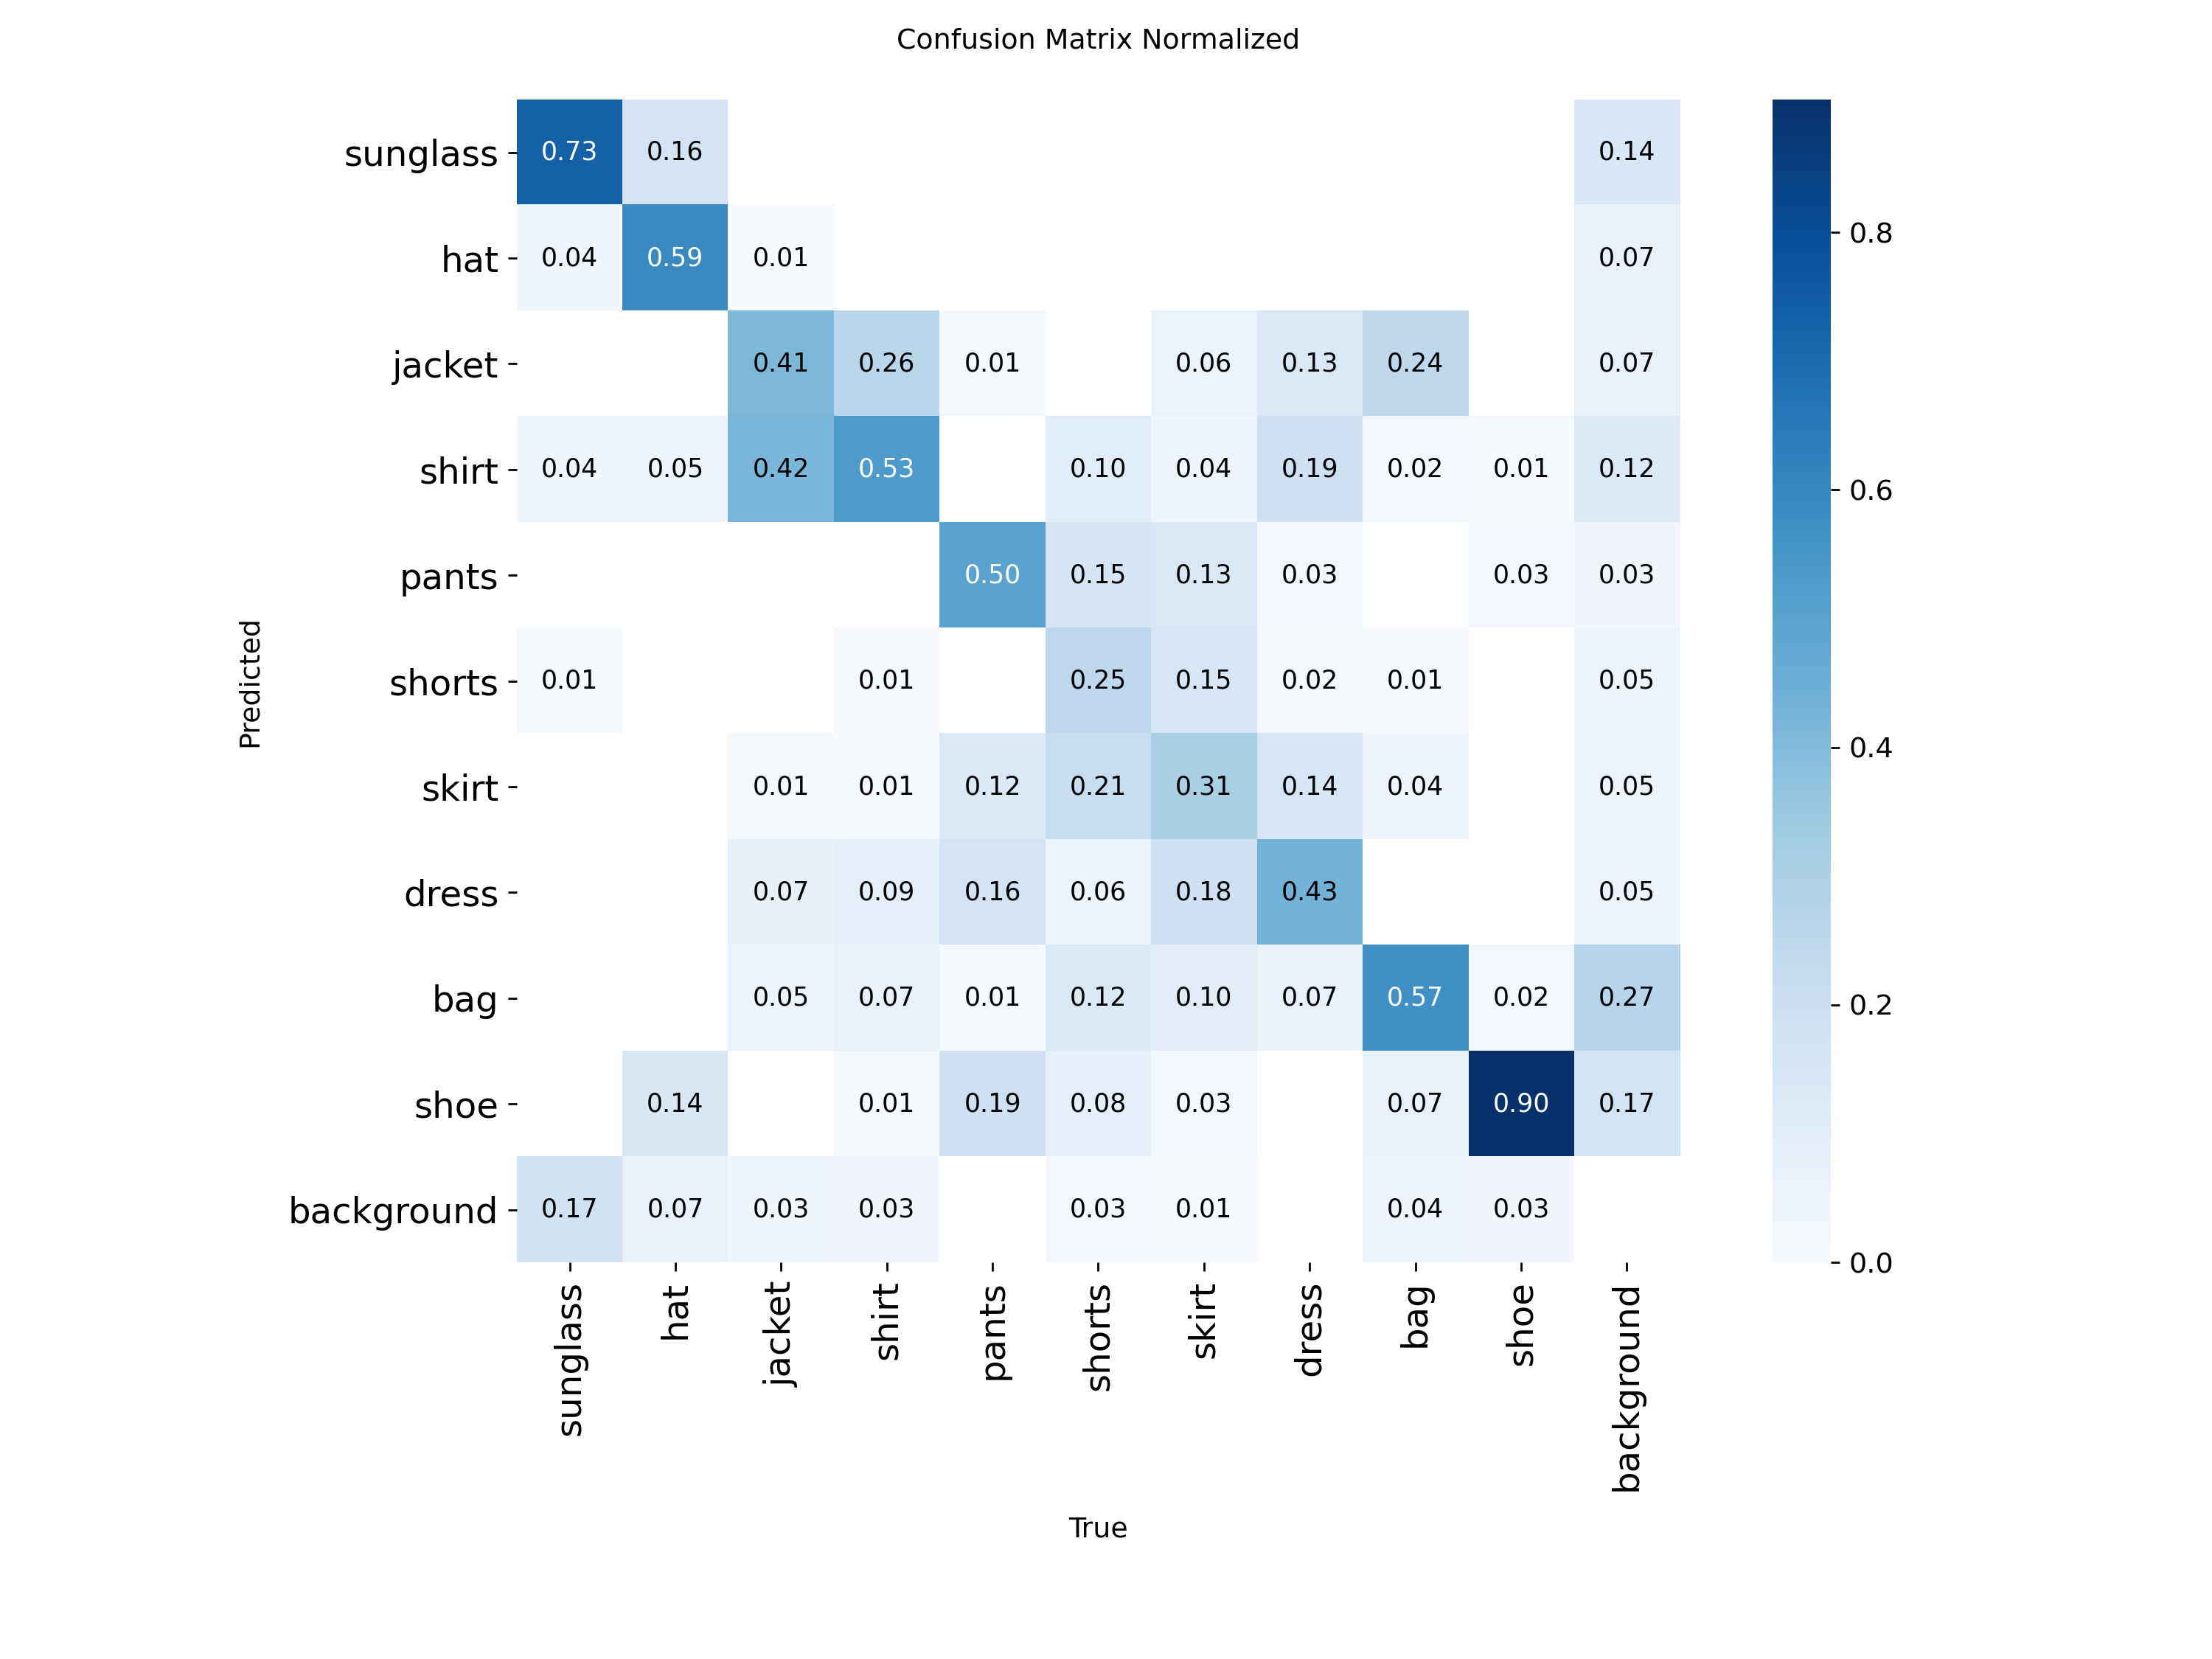

In [17]:
# Show training curves and confusion matrix saved during training
run_dir=os.path.dirname(os.path.dirname(best_model_path))
for plot_name in ["results.png","confusion_matrix_normalized.png"]:
    plot_path=os.path.join(run_dir,plot_name)
    if os.path.exists(plot_path):
        display(IPyImage(filename=plot_path,width=900))
    else:
        print("Not found:",plot_path)

The test images were never used for training or validation, so the next two cells are the final unbiased check.

In [18]:
# Evaluate the trained model on the unseen test set
test_metrics=model.val(data=yaml_path,split="test",imgsz=320,plots=False,verbose=False)
print(f"Test Precision: {test_metrics.box.mp:.3f}")
print(f"Test Recall: {test_metrics.box.mr:.3f}")
print(f"Test mAP50: {test_metrics.box.map50:.3f}")
print(f"Test mAP50-95: {test_metrics.box.map:.3f}")
print("\nmAP50 per class:")
for class_id,ap in zip(test_metrics.box.ap_class_index,test_metrics.box.ap50):
    print(f"  {model.names[int(class_id)]}: {ap:.3f}")

Ultralytics 8.4.182  Python-3.12.15 torch-2.14.1+cpu CPU (AMD Ryzen 3 3250U with Radeon Graphics)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 4.2±0.5 MB/s, size: 49.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\Hope\AI Course Tamil\16. Week-11-Deep Learning Module\4.Assignment\Colorful_Fashion_Project\yolo_dataset\labels\test... 537 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 537/537 98.4it/s 5.5s0.1ss
val: New cache created: D:\Hope\AI Course Tamil\16. Week-11-Deep Learning Module\4.Assignment\Colorful_Fashion_Project\yolo_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 1.1it/s 30.5s0.9ss
                   all        537       2035       0.74      0.706      0.748      0.494

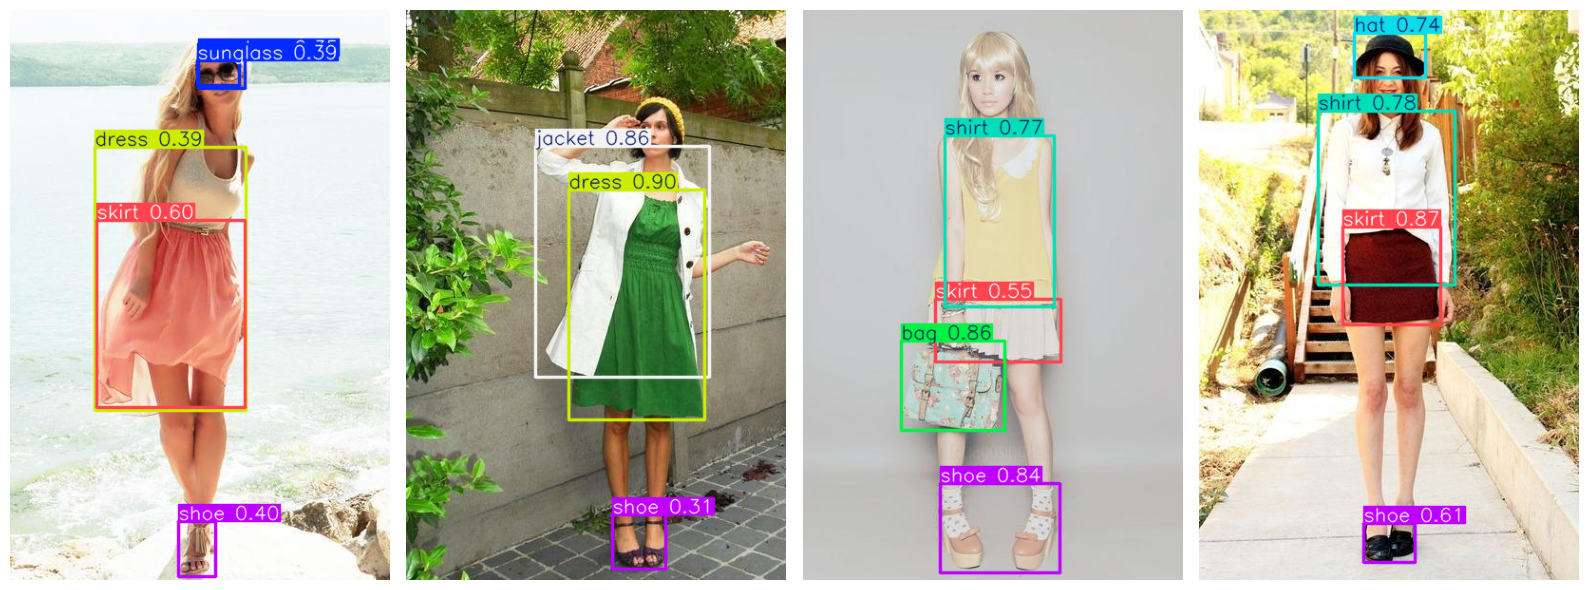

In [19]:
# Detect fashion items in sample test images
sample_ids=test_ids[:4]
fig,axes=plt.subplots(1,4,figsize=(16,6))
for ax,image_id in zip(axes,sample_ids):
    image_path=os.path.join(yolo_dir,"images","test",f"{image_id}.jpg")
    prediction=model.predict(source=image_path,imgsz=320,verbose=False)
    ax.imshow(cv2.cvtColor(prediction[0].plot(),cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.show()